# ENG5338 CW2 — GAS4: gas turbine emissions

**Stage: shared framework and measured linear reference; group decisions pending.**

We investigate a virtual sensor that estimates contemporaneous CO concentration
from nine ambient/process measurements. This is not a future forecast or a certified
emissions compliance system. Target CO, input availability, constraint thresholds,
and validation gap are provisional until agreed by the group.

This notebook is the common source for later experiments. The model pool is fixed: RandomForestRegressor (member 2), ExtraTreesRegressor
(member 3), and HistGradientBoostingRegressor (member 4), plus LinearRegression
as the reference. Only the linear reference runs by default. Unexecuted candidate models are explicitly labelled below. No final
pipeline has been selected and no CW2 held-out performance is reported.

Dataset: course-supplied Moodle CSV; Kaya, Tüfekci and Uzun (2019),
*Gas Turbine CO and NOx Emission Data Set*, UCI, DOI: 10.24432/C5WC95.
The course dataset guide permits CO or NOx, and prohibits TEY as the target.

## 1. Reproducibility and runtime

Run all cells in a fresh kernel. Dependencies and the exact interpreter are recorded.
Use one numerical thread and one search worker for comparable CPU timings. The
supplied dataset is copied unchanged into `data/`; CW1 files are not modified.

In [1]:
import os
for variable in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "NUMEXPR_NUM_THREADS"):
    os.environ[variable] = "1"

import sys, json, hashlib, platform, time, pickle, threading, gc
from datetime import datetime, timezone
from pathlib import Path
from importlib.metadata import version
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import psutil
from IPython.display import display
from threadpoolctl import threadpool_limits, threadpool_info
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, HistGradientBoostingRegressor
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score, make_scorer

THREAD_CONTROLLER = threadpool_limits(limits=1)
SEED = 42
np.random.seed(SEED)
PROJECT = Path.cwd()
if (PROJECT / "ENG5338_CW2").is_dir():
    PROJECT = PROJECT / "ENG5338_CW2"
assert (PROJECT / "data/gas-turbine-emissions.csv").is_file(), "Run from the CW2 folder or its parent."
RESULTS = PROJECT / "results"
RESULTS.mkdir(exist_ok=True)

def public_metadata(value):
    """Redact local home paths in published runtime records."""
    if isinstance(value, dict):
        return {key: public_metadata(item) for key, item in value.items()}
    if isinstance(value, list):
        return [public_metadata(item) for item in value]
    if isinstance(value, str):
        return value.replace(str(Path.home()), "<home>")
    return value

def save_json(name, value):
    (RESULTS / name).write_text(json.dumps(public_metadata(value), indent=2, default=str) + "\n")

PACKAGES = ["numpy", "pandas", "scipy", "scikit-learn", "matplotlib", "psutil",
            "threadpoolctl", "nbformat", "nbclient", "ipykernel"]
cpu_lines = Path("/proc/cpuinfo").read_text().splitlines() if Path("/proc/cpuinfo").exists() else []
cpu_name = next((line.split(":", 1)[1].strip() for line in cpu_lines if line.startswith("model name")), platform.processor())
RUNTIME = {
    "recorded_at_utc": datetime.now(timezone.utc).isoformat(),
    "python": sys.version, "executable": sys.executable, "platform": platform.platform(),
    "cpu": cpu_name, "logical_cpus": os.cpu_count(),
    "ram_gib": psutil.virtual_memory().total / 1024**3,
    "accelerator_used": "CPU only", "numerical_threads": 1, "search_workers": 1,
    "seed": SEED, "versions": {package: version(package) for package in PACKAGES},
    "thread_pools": threadpool_info(),
}
RUNTIME = public_metadata(RUNTIME)
RUNTIME_ID = hashlib.sha256(json.dumps(RUNTIME, sort_keys=True).encode()).hexdigest()[:12]
RUNTIME["runtime_id"] = RUNTIME_ID
save_json("runtime.json", RUNTIME)
display(RUNTIME)

{'recorded_at_utc': '2026-11-07T18:15:49.830089+00:00',
 'python': '3.12.9 | packaged by Anaconda, Inc. | (main, Feb  6 2025, 18:56:27) [GCC 11.2.0]',
 'executable': '<home>/Intro_to_AI_ML/ENG5338_CW1/.venv/bin/python',
 'platform': 'Linux-5.15.0-139-generic-x86_64-with-glibc2.31',
 'cpu': 'AMD Ryzen 7 5800H with Radeon Graphics',
 'logical_cpus': 16,
 'ram_gib': 15.467456817626953,
 'accelerator_used': 'CPU only',
 'numerical_threads': 1,
 'search_workers': 1,
 'seed': 42,
 'versions': {'numpy': '2.5.4',
  'pandas': '3.0.6',
  'scipy': '1.18.1',
  'scikit-learn': '1.9.1',
  'matplotlib': '3.11.2',
  'psutil': '7.2.2',
  'threadpoolctl': '3.7.0',
  'nbformat': '5.11.1',
  'nbclient': '0.11.0',
  'ipykernel': '7.4.0'},
 'thread_pools': [{'user_api': 'blas',
   'internal_api': 'openblas',
   'num_threads': 1,
   'prefix': 'libscipy_openblas',
   'filepath': '<home>/Intro_to_AI_ML/ENG5338_CW1/.venv/lib/python3.12/site-packages/numpy.libs/libscipy_openblas64_-f48b354e.so',
   'version': '0

## 2. Data integrity and sealed hold-out

Global checks inspect schema, missingness, finite values and duplicates only.
All distribution analysis and model selection use 2011–2013 (22,191 rows).
2014–2015 (14,542 rows) are reserved by original row index; their target values are
not passed to an evaluator. Exact timestamps are unavailable: a row gap is not a
verified number of hours. No unverified duplicate or outlier deletion is applied.

**Prior exposure:** the existing CW1 notebook already evaluated 2014–2015. Thus this
is an operationally sealed CW2 hold-out, not a historically unseen dataset. Do not
use CW1 test scores or residuals to choose CW2 settings. Truly fresh generalisation
evidence would require later/external data approved by the course team.

In [2]:
DATA_PATH = PROJECT / "data/gas-turbine-emissions.csv"
DATA_SHA256 = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
assert DATA_SHA256 == "6295ecd391e757ab5e029bdb54aee607887374861f656a26281b5a0e4e524b85"
raw = pd.read_csv(DATA_PATH)
EXPECTED = ["year", "at", "ap", "ah", "afdp", "gtep", "tit", "tat", "tey", "cdp", "co", "nox"]
assert raw.columns.tolist() == EXPECTED and raw.shape == (36733, 12)
assert raw.year.is_monotonic_increasing
assert all(pd.api.types.is_numeric_dtype(raw[column]) for column in EXPECTED)
assert np.isfinite(raw.to_numpy()).all()
schema = pd.DataFrame({"dtype": raw.dtypes.astype(str), "missing": raw.isna().sum()})
display(schema)
schema.to_csv(RESULTS / "schema.csv")
print("Exact duplicate complete rows:", int(raw.duplicated().sum()))
display(raw.groupby("year").size().rename("rows").to_frame())

development_ids = raw.index[raw.year.isin([2011, 2012, 2013])].to_numpy()
holdout_ids = raw.index[raw.year.isin([2014, 2015])].to_numpy()
assert len(development_ids) == 22191 and len(holdout_ids) == 14542
assert development_ids.max() < holdout_ids.min()
assert len(np.intersect1d(development_ids, holdout_ids)) == 0
assert len(development_ids) + len(holdout_ids) == len(raw)
split_manifest = pd.DataFrame({"source_row": raw.index,
    "partition": np.where(raw.year <= 2013, "development", "sealed_holdout")})
split_manifest.to_csv(RESULTS / "split_manifest.csv", index=False)
development = raw.loc[development_ids].copy()
del raw  # No held-out feature/target objects are retained for model experiments.
save_json("data_provenance.json", {"path": str(DATA_PATH), "sha256": DATA_SHA256,
    "source": "Unmodified course CSV copied from CW1", "development_rows": len(development_ids),
    "holdout_rows": len(holdout_ids), "prior_cw1_test_exposure": True})

,dtype,missing
year,int64,0
at,float64,0
ap,float64,0
ah,float64,0
afdp,float64,0
gtep,float64,0
tit,float64,0
tat,float64,0
tey,float64,0
cdp,float64,0


Exact duplicate complete rows: 7


,rows
year,
2011,7411
2012,7628
2013,7152
2014,7158
2015,7384


In [3]:
development_overview = pd.DataFrame({
    "missing": development.isna().sum(), "distinct": development.nunique(),
    "minimum": development.min(), "median": development.median(), "maximum": development.max()})
display(development_overview)
development_overview.to_csv(RESULTS / "development_overview.csv")
display(development[["co", "nox"]].describe(percentiles=[.05, .5, .9, .95, .99]).T)
print("Development duplicate rows:", int(development.duplicated().sum()))
print("Development humidity above 100%:", int((development.ah > 100).sum()))
print("Values are retained pending evidence of recording errors.")

,missing,distinct,minimum,median,maximum
year,0,3,2011.000000,2012.0000,2013.0000
at,0,15988,0.289850,17.7390,34.9290
ap,0,670,985.850000,1012.4000,1034.2000
ah,0,17316,27.504000,82.7810,100.2000
afdp,0,15228,2.087400,4.0688,7.6106
gtep,0,9827,17.878000,24.9890,37.4020
tit,0,722,1000.800000,1088.1000,1100.8000
tat,0,2587,512.450000,549.9000,550.6100
tey,0,5013,100.170000,133.7700,174.6100
cdp,0,3977,9.875400,12.0010,15.0810


,count,mean,std,min,5%,50%,90%,95%,99%,max
co,22191.0,2.214390,2.295746,0.000388,0.375205,1.5242,4.815,6.1675,10.7166,44.103
nox,22191.0,68.776529,11.036231,27.765000,53.694000,67.0960,82.133,87.1325,107.4520,119.910


Development duplicate rows: 0
Development humidity above 100%: 380
Values are retained pending evidence of recording errors.


## 3. Provisional engineering protocol — group agreement required

Question: can nine contemporaneous process/environmental sensors estimate CO for
operator monitoring without using another pollutant analyser (NOx)? TEY is available
only if its hourly measurement is ready at prediction time; verify this assumption.

Proposed requirements (engineering assumptions, not legal or manufacturer limits):
1. At least 90% of observations have absolute CO error <= 1 mg/m³. CO is near zero
   in some development rows, making percentage error unstable. The numerical
   tolerance and coverage must be agreed with an operational stakeholder/group.
2. Median complete-pipeline single-row prediction latency <= 10 ms on the recorded
   single-thread CPU, after warm-up. This is a provisional software service budget
   for an hourly monitoring workflow, not a property established by the dataset.

Primary tuning metric: MAE (mg/m³); also RMSE, R², coverage, training/validation gap
and negative-prediction fraction. The two constraints are checked jointly; lowest
MAE alone does not establish feasibility. If no candidate satisfies the agreed
constraints, report no feasible candidate rather than changing thresholds to pass.

Five expanding chronological folds, with a provisional gap of 24 rows, are identical
for every model. The gap reduces immediate neighbour leakage but does not guarantee
independence. Gap 0/168 and whole-year validation are planned sensitivity analyses
only, not executed in this framework. Lock one protocol before group comparisons.

In [4]:
TARGET = "co"  # Group decision pending; only "co" or "nox" is allowed.
assert TARGET in {"co", "nox"}
FEATURES = ["at", "ap", "ah", "afdp", "gtep", "tit", "tat", "tey", "cdp"]
TOLERANCE = 1.0
MIN_COVERAGE = 0.90
MAX_MEDIAN_SINGLE_MS = 10.0
GAP_ROWS = 24
X_dev = development[FEATURES].copy()
y_dev = development[TARGET].copy()
FOLDS = list(TimeSeriesSplit(n_splits=5, gap=GAP_ROWS).split(X_dev))
fold_records = []
for number, (train_index, validation_index) in enumerate(FOLDS, 1):
    assert train_index.max() + GAP_ROWS < validation_index.min()
    fold_records.append({"fold": number, "train_n": len(train_index), "validation_n": len(validation_index),
        "train_last_row": int(X_dev.index[train_index[-1]]),
        "validation_first_row": int(X_dev.index[validation_index[0]]),
        "validation_last_row": int(X_dev.index[validation_index[-1]]),
        "train_last_year": int(development.iloc[train_index[-1]].year),
        "validation_first_year": int(development.iloc[validation_index[0]].year),
        "validation_last_year": int(development.iloc[validation_index[-1]].year)})
fold_table = pd.DataFrame(fold_records)
display(fold_table)
fold_table.to_csv(RESULTS / "folds.csv", index=False)
PROTOCOL = {"target": TARGET, "features": FEATURES, "data_sha256": DATA_SHA256,
    "development_years": [2011, 2012, 2013], "sealed_holdout_years": [2014, 2015],
    "seed": SEED, "folds": 5, "gap_rows": GAP_ROWS, "primary_metric": "MAE",
    "tolerance": TOLERANCE, "min_coverage": MIN_COVERAGE,
    "max_median_single_ms": MAX_MEDIAN_SINGLE_MS, "group_approved": False}
PROTOCOL_ID = hashlib.sha256(json.dumps(PROTOCOL, sort_keys=True).encode()).hexdigest()[:12]
save_json("protocol_draft.json", {**PROTOCOL, "protocol_id": PROTOCOL_ID})

,fold,train_n,validation_n,train_last_row,validation_first_row,validation_last_row,train_last_year,validation_first_year,validation_last_year
0,1,3677,3698,3676,3701,7398,2011,2011,2011
1,2,7375,3698,7374,7399,11096,2011,2011,2012
2,3,11073,3698,11072,11097,14794,2012,2012,2012
3,4,14771,3698,14770,14795,18492,2012,2012,2013
4,5,18469,3698,18468,18493,22190,2013,2013,2013


In [5]:
def tolerance_coverage(y_true, y_pred):
    """Fraction within the predeclared absolute tolerance; larger is better."""
    return float(np.mean(np.abs(np.asarray(y_true) - np.asarray(y_pred)) <= TOLERANCE))

def negative_fraction(y_true, y_pred):
    return float(np.mean(np.asarray(y_pred) < 0))

def regression_metrics(y_true, y_pred):
    """Shared metrics for development diagnostics and a future locked evaluation."""
    return {"mae": mean_absolute_error(y_true, y_pred),
            "rmse": root_mean_squared_error(y_true, y_pred), "r2": r2_score(y_true, y_pred),
            "coverage": tolerance_coverage(y_true, y_pred),
            "negative_fraction": negative_fraction(y_true, y_pred)}

SCORING = {"mae": "neg_mean_absolute_error", "rmse": "neg_root_mean_squared_error",
           "r2": "r2", "coverage": make_scorer(tolerance_coverage),
           "negative_fraction": make_scorer(negative_fraction, greater_is_better=False)}

def pipeline_for(estimator, scale=False):
    steps = [("impute", SimpleImputer(strategy="median"))]
    if scale:
        steps.append(("scale", StandardScaler()))
    return Pipeline(steps + [("model", estimator)])

def run_search(name, estimator, parameter_grid):
    """Fit/tune on development folds only; never accepts a hold-out argument."""
    started = time.perf_counter()
    search = GridSearchCV(estimator, parameter_grid, cv=FOLDS, scoring=SCORING,
        refit="mae", return_train_score=True, n_jobs=1, error_score="raise")
    search.fit(X_dev, y_dev)
    elapsed = time.perf_counter() - started
    grid = pd.DataFrame(search.cv_results_)
    grid.to_csv(RESULTS / f"{name}_search.csv", index=False)
    best = grid.iloc[search.best_index_]
    records = []
    for fold in range(len(FOLDS)):
        record = {"model": name, "fold": fold + 1, "protocol_id": PROTOCOL_ID}
        for subset, key in [("train", "train"), ("validation", "test")]:
            for metric in SCORING:
                sign = -1 if metric in {"mae", "rmse", "negative_fraction"} else 1
                record[f"{subset}_{metric}"] = sign * best[f"split{fold}_{key}_{metric}"]
        record["mae_gap"] = record["validation_mae"] - record["train_mae"]
        records.append(record)
    details = pd.DataFrame(records)
    details.to_csv(RESULTS / f"{name}_fold_metrics.csv", index=False)
    summary = {"model": name, "status": "RUN: development only", "protocol_id": PROTOCOL_ID,
        "runtime_id": RUNTIME_ID, "best_params": search.best_params_,
        "train_mae": details.train_mae.mean(), "validation_mae": details.validation_mae.mean(),
        "validation_mae_sd": details.validation_mae.std(ddof=0),
        "validation_rmse": details.validation_rmse.mean(), "validation_r2": details.validation_r2.mean(),
        "validation_coverage": details.validation_coverage.mean(),
        "worst_fold_coverage": details.validation_coverage.min(),
        "mae_gap": details.mae_gap.mean(), "search_wall_s": elapsed,
        "configurations": len(grid), "cv_fits": len(grid) * len(FOLDS),
        "refit_s": search.refit_time_}
    save_json(f"{name}_summary.json", summary)
    return search, details, summary

print("All preprocessing is fitted inside the pipeline, separately in each training fold.")

All preprocessing is fitted inside the pipeline, separately in each training fold.


## 4. Measured linear regression reference

OLS has no regularisation hyperparameter; its single fixed configuration uses the
same search/evaluation path as the candidate models. Imputation and standardisation
are learned only from each fold's training observations. No post-hoc clipping or
target transformation is applied. Fold standard deviation describes temporal
variation, not a confidence interval. Scores used for tuning can be optimistic.

In [6]:
SEARCHES, SUMMARIES = {}, []
linear_pipeline = pipeline_for(LinearRegression(), scale=True)
linear_search, linear_folds, linear_summary = run_search("linear_reference", linear_pipeline, {})
SEARCHES["linear_reference"] = linear_search
SUMMARIES.append(linear_summary)
display(linear_folds)
display(pd.DataFrame(SUMMARIES))

# Audit one fold's preprocessing statistics against its own training data.
first_train, first_validation = FOLDS[0]
audit = clone(linear_pipeline).fit(X_dev.iloc[first_train], y_dev.iloc[first_train])
np.testing.assert_allclose(audit.named_steps["impute"].statistics_, X_dev.iloc[first_train].median())
np.testing.assert_allclose(audit.named_steps["scale"].mean_, X_dev.iloc[first_train].mean())
print("Fold-local preprocessing audit passed; held-out scores have not been computed.")

,model,fold,protocol_id,train_mae,train_rmse,train_r2,train_coverage,train_negative_fraction,validation_mae,validation_rmse,validation_r2,validation_coverage,validation_negative_fraction,mae_gap
0,linear_reference,1,454f332babc7,0.460571,0.816260,0.476204,0.923851,0.000000,0.717657,1.685591,0.471155,0.845592,0.000000,0.257086
1,linear_reference,2,454f332babc7,0.631866,1.278416,0.517369,0.825763,0.015051,0.807250,1.960606,0.471539,0.753110,0.017577,0.175384
2,linear_reference,3,454f332babc7,0.712354,1.518254,0.519148,0.788224,0.008489,1.082914,1.714724,0.391779,0.573824,0.030827,0.370560
3,linear_reference,4,454f332babc7,0.759298,1.534510,0.518618,0.786338,0.004739,1.088565,1.631554,0.639211,0.642780,0.000270,0.329267
4,linear_reference,5,454f332babc7,0.801923,1.503361,0.595101,0.759164,0.008176,0.840211,1.453751,0.428768,0.774743,0.014332,0.038288


,model,status,protocol_id,runtime_id,best_params,train_mae,validation_mae,validation_mae_sd,validation_rmse,validation_r2,validation_coverage,worst_fold_coverage,mae_gap,search_wall_s,configurations,cv_fits,refit_s
0,linear_reference,RUN: development only,454f332babc7,32562bd19d88,{},0.673202,0.907319,0.151111,1.689245,0.480491,0.71801,0.573824,0.234117,0.147214,1,5,0.015559


Fold-local preprocessing audit passed; held-out scores have not been computed.


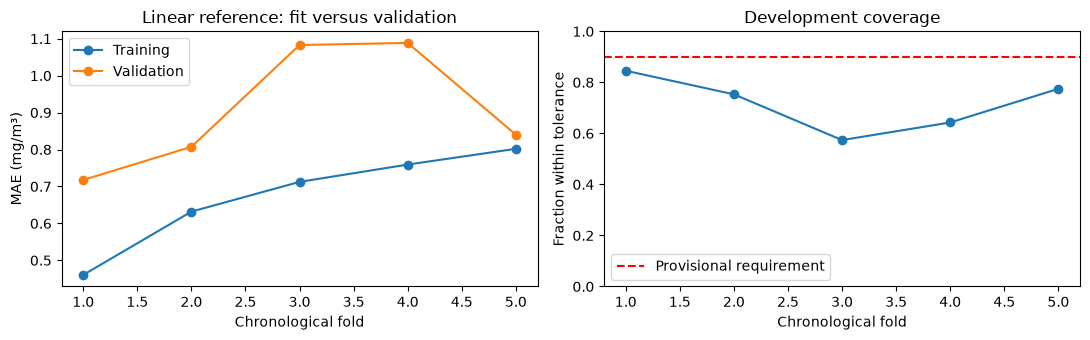

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].plot(linear_folds.fold, linear_folds.train_mae, "o-", label="Training")
axes[0].plot(linear_folds.fold, linear_folds.validation_mae, "o-", label="Validation")
axes[0].set(xlabel="Chronological fold", ylabel="MAE (mg/m³)", title="Linear reference: fit versus validation")
axes[0].legend()
axes[1].plot(linear_folds.fold, linear_folds.validation_coverage, "o-")
axes[1].axhline(MIN_COVERAGE, color="red", linestyle="--", label="Provisional requirement")
axes[1].set(xlabel="Chronological fold", ylabel="Fraction within tolerance", ylim=(0, 1), title="Development coverage")
axes[1].legend()
fig.tight_layout()
fig.savefig(RESULTS / "linear_reference_cv.png", dpi=150)
plt.show()

## 5. Shared cost measurements — development inputs only

Measure complete pipelines, including preprocessing. Three independent full-development
fits follow one unrecorded warm-up; report median and raw samples. Search wall time
is separate and includes scoring/refit overhead. Prediction uses a fixed 1,000-row
development batch and one fixed row; warm up then report 10 batch and 100 single-row
samples. Batch amortised cost is not single-observation latency. These are local Python
calls, excluding sensor acquisition, transport and service overhead.

Memory is sampled process RSS increase above baseline during a **separate** fit,
at approximately 5 ms intervals. Sampling and allocator reuse can miss peaks; zero
does not imply zero memory. Serialized pipeline bytes measure artifact size, not RAM.
All models must use the same interpreter, thread limits and benchmark inputs.

In [8]:
def sample_seconds(operation, repeats, warmup=1):
    for _ in range(warmup):
        operation()
    samples = []
    for _ in range(repeats):
        start = time.perf_counter()
        operation()
        samples.append(time.perf_counter() - start)
    return samples

BENCHMARK_BATCH = X_dev.iloc[-1000:].copy()
BENCHMARK_SINGLE = BENCHMARK_BATCH.iloc[[0]].copy()

def benchmark_pipeline(name, configured_pipeline):
    fit_samples = sample_seconds(lambda: clone(configured_pipeline).fit(X_dev, y_dev), 3)
    fitted = clone(configured_pipeline).fit(X_dev, y_dev)
    batch_samples = sample_seconds(lambda: fitted.predict(BENCHMARK_BATCH), 10, warmup=3)
    single_samples = sample_seconds(lambda: fitted.predict(BENCHMARK_SINGLE), 100, warmup=5)
    gc.collect()
    process = psutil.Process()
    baseline = process.memory_info().rss
    peak = [baseline]
    stop = threading.Event()
    def watch_memory():
        while not stop.is_set():
            peak[0] = max(peak[0], process.memory_info().rss)
            stop.wait(0.005)
    watcher = threading.Thread(target=watch_memory, daemon=True)
    watcher.start()
    try:
        memory_fit = clone(configured_pipeline).fit(X_dev, y_dev)
        peak[0] = max(peak[0], process.memory_info().rss)
    finally:
        stop.set()
        watcher.join()
    result = {"model": name, "runtime_id": RUNTIME_ID, "protocol_id": PROTOCOL_ID,
        "train_rows": len(X_dev), "batch_rows": len(BENCHMARK_BATCH),
        "fit_median_s": float(np.median(fit_samples)),
        "single_median_ms": float(np.median(single_samples) * 1000),
        "single_p95_ms": float(np.quantile(single_samples, .95) * 1000),
        "batch_1000_median_ms": float(np.median(batch_samples) * 1000),
        "batch_amortised_us_per_row": float(np.median(batch_samples) * 1e6 / len(BENCHMARK_BATCH)),
        "fit_sampled_rss_increment_mib": (peak[0] - baseline) / 1024**2,
        "serialized_pipeline_kib": len(pickle.dumps(fitted)) / 1024,
        "fit_samples_s": fit_samples, "single_samples_s": single_samples, "batch_samples_s": batch_samples,
        "memory_method": "Process RSS increase; separate fit; sampled every ~5 ms"}
    save_json(f"{name}_benchmark.json", result)
    return result

COSTS = [benchmark_pipeline("linear_reference", linear_search.best_estimator_)]
display(pd.DataFrame(COSTS).drop(columns=["fit_samples_s", "single_samples_s", "batch_samples_s"]))

,model,runtime_id,protocol_id,train_rows,batch_rows,fit_median_s,single_median_ms,single_p95_ms,batch_1000_median_ms,batch_amortised_us_per_row,fit_sampled_rss_increment_mib,serialized_pipeline_kib,memory_method
0,linear_reference,32562bd19d88,454f332babc7,22191,1000,0.014909,1.023609,1.089774,1.152398,1.152398,0.0,1.62793,Process RSS increase; separate fit; sampled ev...


## 6. Model-owner experiments — NOT RUN by default

Three candidates in addition to the linear reference:

| Owner slot | Model | Reason and planned tuning |
|---|---|---|
| A | Random forest | Nonlinear interactions; control depth/leaves to limit variance; 8 configurations |
| B | Extra Trees | More random splits may reduce variance/cost; same 8-configuration budget |
| C | Histogram gradient boosting | Sequential nonlinear residual corrections; 8 configurations |

These are hypotheses, not measured comparative findings. Each candidate has 40 CV
fits plus one development refit. HGB internal random early stopping is disabled to
preserve chronological validation. Owners should justify any grid expansion using
development evidence, log it, and rerun comparisons under a common protocol.

In [9]:
CANDIDATES = {
    "random_forest": (pipeline_for(RandomForestRegressor(random_state=SEED, n_jobs=1, max_features=.8)),
        {"model__n_estimators": [100, 300], "model__max_depth": [8, None], "model__min_samples_leaf": [2, 10]}),
    "extra_trees": (pipeline_for(ExtraTreesRegressor(random_state=SEED, n_jobs=1, max_features=.8)),
        {"model__n_estimators": [100, 300], "model__max_depth": [8, None], "model__min_samples_leaf": [2, 10]}),
    "hist_gradient_boosting": (pipeline_for(HistGradientBoostingRegressor(
        random_state=SEED, early_stopping=False, max_iter=200)),
        {"model__learning_rate": [.05, .1], "model__max_leaf_nodes": [15, 31], "model__l2_regularization": [0., 1.]}),
}
RUN_MODELS = {name: False for name in CANDIDATES}  # Set True to run the assigned experiment.

### Owner A: Random Forest

**Pending:** add name/ID, development-only tuning rationale, observations on
train/validation gaps, limitations and reviewed contribution. Model results are
not available until the following experiment is enabled and executed.

In [10]:
if RUN_MODELS["random_forest"]:
    candidate, grid = CANDIDATES["random_forest"]
    search, folds, summary = run_search("random_forest", candidate, grid)
    SEARCHES["random_forest"] = search
    SUMMARIES.append(summary)
    COSTS.append(benchmark_pipeline("random_forest", search.best_estimator_))
    display(folds)
else:
    print("NOT RUN: random_forest; no performance claim available.")

NOT RUN: random_forest; no performance claim available.


### Owner B: Extra Trees

**Pending:** add name/ID, development-only tuning rationale, observations on
train/validation gaps, limitations and reviewed contribution. Model results are
not available until the following experiment is enabled and executed.

In [11]:
if RUN_MODELS["extra_trees"]:
    candidate, grid = CANDIDATES["extra_trees"]
    search, folds, summary = run_search("extra_trees", candidate, grid)
    SEARCHES["extra_trees"] = search
    SUMMARIES.append(summary)
    COSTS.append(benchmark_pipeline("extra_trees", search.best_estimator_))
    display(folds)
else:
    print("NOT RUN: extra_trees; no performance claim available.")

NOT RUN: extra_trees; no performance claim available.


### Owner C: Hist Gradient Boosting

**Pending:** add name/ID, development-only tuning rationale, observations on
train/validation gaps, limitations and reviewed contribution. Model results are
not available until the following experiment is enabled and executed.

In [12]:
if RUN_MODELS["hist_gradient_boosting"]:
    candidate, grid = CANDIDATES["hist_gradient_boosting"]
    search, folds, summary = run_search("hist_gradient_boosting", candidate, grid)
    SEARCHES["hist_gradient_boosting"] = search
    SUMMARIES.append(summary)
    COSTS.append(benchmark_pipeline("hist_gradient_boosting", search.best_estimator_))
    display(folds)
else:
    print("NOT RUN: hist_gradient_boosting; no performance claim available.")

NOT RUN: hist_gradient_boosting; no performance claim available.


## 7. Common comparison and feasibility screen

Both constraints are provisional. Mean validation coverage describes equal-size
validation blocks; worst-fold coverage shows temporal robustness separately. A pass
here is a development screen, not a production guarantee or a final recommendation.
Model selection after tuning on the same CV folds can be optimistic; the reserved
test is for one locked model only. Do not rank missing or unexecuted candidates.

In [13]:
comparison = pd.DataFrame(SUMMARIES).merge(pd.DataFrame(COSTS)[[
    "model", "fit_median_s", "single_median_ms", "single_p95_ms", "batch_1000_median_ms",
    "fit_sampled_rss_increment_mib", "serialized_pipeline_kib"]], on="model", validate="one_to_one")
comparison["provisional_constraints_met"] = (
    (comparison.validation_coverage >= MIN_COVERAGE) &
    (comparison.single_median_ms <= MAX_MEDIAN_SINGLE_MS))
comparison.to_csv(RESULTS / "development_comparison.csv", index=False)
display(comparison)
status = pd.DataFrame([{"model": name,
    "status": "RUN: development only" if name in SEARCHES else "NOT RUN"}
    for name in ["linear_reference", *CANDIDATES]])
status.to_csv(RESULTS / "experiment_status.csv", index=False)
display(status)
print("No final model selected. Constraints and protocol require group agreement.")

,model,status,protocol_id,runtime_id,best_params,train_mae,validation_mae,validation_mae_sd,validation_rmse,validation_r2,...,configurations,cv_fits,refit_s,fit_median_s,single_median_ms,single_p95_ms,batch_1000_median_ms,fit_sampled_rss_increment_mib,serialized_pipeline_kib,provisional_constraints_met
0,linear_reference,RUN: development only,454f332babc7,32562bd19d88,{},0.673202,0.907319,0.151111,1.689245,0.480491,...,1,5,0.015559,0.014909,1.023609,1.089774,1.152398,0.0,1.62793,False


,model,status
0,linear_reference,RUN: development only
1,random_forest,NOT RUN
2,extra_trees,NOT RUN
3,hist_gradient_boosting,NOT RUN


No final model selected. Constraints and protocol require group agreement.


## 8. Validation owner's extensions — NOT RUN

Before final selection, use development data only to:
- Plot each tuned model's training and validation MAE by fold and hyperparameter;
  assess whether depth/leaf size/regularisation reduces the gap and validation error.
- Compare gap 0/24/168 and whole-year validation for sensitivity, using identical
  splits across candidates. Interpret time drift separately from model variance.
- Inspect out-of-fold residuals and high-CO errors, defining any tail threshold from
  each fold's training targets. Keep negative outputs visible unless clipping is
  predeclared and compared as a separate pipeline using development data only.
- Measure training scalability on chronological 25/50/100% prefixes, same sizes for
  all candidates, with repeated fits and memory estimates. A size change also changes
  temporal coverage; it is not a pure sample-size accuracy experiment.
- If validation uncertainty drives the decision, consider nested chronological CV;
  do not describe tuning-fold scores as unbiased out-of-sample estimates.

Add executed code and outputs here. No learning-curve, sensitivity, tail-error or
scalability results have been produced by this framework.

In [14]:
# Validation owner: add development-only diagnostic experiments here.
# Reuse FEATURES, FOLDS, SCORING and the shared benchmark functions.
print("NOT RUN: extended validation and scalability experiments.")

NOT RUN: extended validation and scalability experiments.


## 9. Final model lock and single held-out evaluation — SEALED / NOT RUN

This framework intentionally contains no held-out prediction call. After the group
agrees the question, constraints and protocol, completes all candidate experiments,
and chooses a feasible pipeline (or documents that none is feasible):

1. Save a reviewed selection record containing group approval, dataset hash,
   protocol, features, preprocessing, chosen family and exact parameters, decision
   evidence and limitations; hash the complete record before opening the hold-out.
2. Fit the frozen pipeline on all development rows. Load only the reserved rows
   from the hash-verified CSV, and predict once for that single pipeline.
3. Derive the predeclared metrics and constraint checks from that one prediction
   vector. Persist it with source-row IDs, model-lock hash and runtime. Refuse a
   second test evaluation if a final-test artifact already exists.
4. If test constraints fail, report failure and limitations. No retuning, model
   switching or threshold adjustment using this test. New development needs new
   independent evaluation data.

**No model lock or final test results exist at this stage.**

In [15]:
assert "X_test" not in globals() and "y_test" not in globals()
assert not (RESULTS / "final_test_metrics.json").exists()
assert all(summary["protocol_id"] == PROTOCOL_ID for summary in SUMMARIES)
assert np.isfinite(comparison[["train_mae", "validation_mae", "validation_rmse", "validation_r2"]]).all().all()
print("Framework audit passed. CW2 final evaluation remains sealed.")

Framework audit passed. CW2 final evaluation remains sealed.


## 10. Contributions and AI assistance — living record

The allocation below is proposed work, not evidence of completed contributions.
Replace placeholders with real names/IDs and record dated implementation, writing,
review and notebook locations. Do not assign AI-generated code to a human without
recording their actual review/adaptation. All members must read and agree the final
statement, and be able to explain every notebook section during Q&A.

| Member | Proposed ownership | Actual implementation / writing / review | Notebook location |
|---|---|---|---|
| A: name/ID pending | Random forest | Pending | 6, owner A |
| B: name/ID pending | Extra Trees | Pending | 6, owner B |
| C: name/ID pending | Histogram gradient boosting | Pending | 6, owner C |
| D: name/ID pending | Data, protocol, validation, linear reference | Pending human review | 1–4, 8 |
| E: name/ID pending | Cost, final lock/test, integration | Pending human review | 5, 7, 9 |

Background research, writing and Q&A preparation are shared. A role is not an
exclusive limit on contribution.

**AI assistance:** OpenAI Codex/ChatGPT inspected the supplied brief/templates,
course dataset guide and CW1 notebook; proposed engineering questions, constraints,
model grids and a validation protocol; generated this shared notebook, executed
the linear reference and its cost measurements, and prepared Chinese study notes.
No AI-generated candidate results or final-test scores are claimed. Human agreement,
technical review and individual understanding are pending. Append later AI use and
human changes to `notes/contributions_and_ai.md`.